In [307]:
#uploading the Data
from google.colab import files
uploaded = files.upload()  # a file picker will pop up

In [308]:
!pwd

/content


In [309]:
!ls

gender_submission.csv  sample_data  sub.csv  test.csv  titanic.zip  train.csv


In [310]:
#making the imports
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path
from torch import nn, tensor
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms, models
from torchvision.transforms import functional as TF
from fastai.vision.all import *
from fastai.callback.hook import *
import zipfile
from pathlib import Path

In [311]:
#unzip files
data_path = Path("titanic.zip")
with zipfile.ZipFile(data_path, 'r') as zip_f:
    zip_f.extractall()

# *data cleaning and exploration*

In [312]:
df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [313]:
df.isna()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,False,False,False,False,False,False,False,False,False,False,True,False
1,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,True,False
3,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
886,False,False,False,False,False,False,False,False,False,False,True,False
887,False,False,False,False,False,False,False,False,False,False,False,False
888,False,False,False,False,False,True,False,False,False,False,True,False
889,False,False,False,False,False,False,False,False,False,False,False,False


In [314]:
df.isna().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [315]:
#cleaning the dataset
modes = df.mode()
modes

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0.0,3.0,"Abbing, Mr. Anthony",male,24.0,0.0,0.0,1601,8.05,B96 B98,S
1,2,NaN,NaN,"Abbott, Mr. Rossmore Edward",NaN,NaN,NaN,NaN,347082,NaN,C23 C25 C27,NaN
2,3,NaN,NaN,"Abbott, Mrs. Stanton (Rosa Hunt)",NaN,NaN,NaN,NaN,CA. 2343,NaN,G6,NaN
3,4,NaN,NaN,"Abelson, Mr. Samuel",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,NaN,NaN,"Abelson, Mrs. Samuel (Hannah Wizosky)",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,NaN,NaN,"de Mulder, Mr. Theodore",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
887,888,NaN,NaN,"de Pelsmaeker, Mr. Alfons",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
888,889,NaN,NaN,"del Carlo, Mr. Sebastiano",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
889,890,NaN,NaN,"van Billiard, Mr. Austin Blyler",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [316]:
modes=modes.iloc[0]
modes

,0
PassengerId,1
Survived,0.0
Pclass,3.0
Name,"Abbing, Mr. Anthony"
Sex,male
Age,24.0
SibSp,0.0
Parch,0.0
Ticket,1601
Fare,8.05


In [317]:
#now lets fill in the missing values by those values
df.fillna(modes,
          inplace=True)#means the change is applied directly to the original dataframe instead of returning a new one.

In [318]:
df.isna().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [319]:
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,B96 B98,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,B96 B98,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,B96 B98,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,B96 B98,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,24.0,1,2,W./C. 6607,23.4500,B96 B98,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [320]:
#see a summery of the Data
df.describe(include=(np.number)).round(2)# to get just the numeric

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.00,891.00,891.00,891.00,891.00,891.00,891.00
mean,446.00,0.38,2.31,28.57,0.52,0.38,32.20
std,257.35,0.49,0.84,13.20,1.10,0.81,49.69
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00
25%,223.50,0.00,2.00,22.00,0.00,0.00,7.91
50%,446.00,0.00,3.00,24.00,0.00,0.00,14.45
75%,668.50,1.00,3.00,35.00,1.00,0.00,31.00
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33


<Axes: >

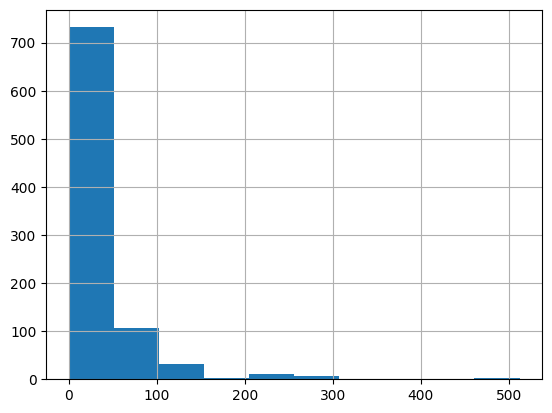

In [321]:
#see the fare(money) problem using the histogram
df["Fare"].hist()

<Axes: >

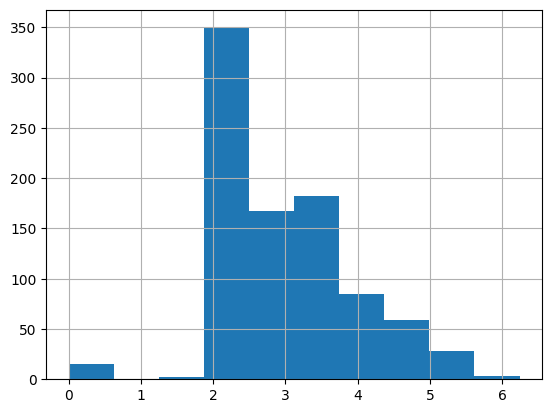

In [322]:
#solve this problem takinng the log
df['LogFare'] = np.log(df["Fare"]+1) # +1 is to avoid log(0) = infinite
df['LogFare'].hist()

In [323]:
pclasses = sorted(df.Pclass.unique().tolist())
pclasses

[1, 2, 3]

In [324]:
#now for the non-numeric(object)
df.describe(include=[object])

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,891,891
unique,891,2,681,147,3
top,"Dooley, Mr. Patrick",male,347082,B96 B98,S
freq,1,577,7,691,646


In [325]:
df.iloc[1]

,1
PassengerId,2
Survived,1
Pclass,1
Name,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)"
Sex,female
Age,38.0
SibSp,1
Parch,0
Ticket,PC 17599
Fare,71.2833


In [326]:
#make the dummy variables
df = pd.get_dummies(df,columns=["Sex","Pclass","Embarked"])
df.columns

Index(['PassengerId', 'Survived', 'Name', 'Age', 'SibSp', 'Parch', 'Ticket',
       'Fare', 'Cabin', 'LogFare', 'Sex_female', 'Sex_male', 'Pclass_1',
       'Pclass_2', 'Pclass_3', 'Embarked_C', 'Embarked_Q', 'Embarked_S'],
      dtype='object')

In [327]:
df.iloc[5]

,5
PassengerId,6
Survived,0
Name,"Moran, Mr. James"
Age,24.0
SibSp,0
Parch,0
Ticket,330877
Fare,8.4583
Cabin,B96 B98
LogFare,2.246893


In [328]:
#visualize
added_cols = ['Sex_male', 'Sex_female', 'Pclass_1', 'Pclass_2', 'Pclass_3', 'Embarked_C', 'Embarked_Q', 'Embarked_S']
df[added_cols].head(2)

,Sex_male,Sex_female,Pclass_1,Pclass_2,Pclass_3,Embarked_C,Embarked_Q,Embarked_S
0,True,False,False,False,True,False,False,True
1,False,True,True,False,False,True,False,False


In [329]:
# this is the thing that we are trying to predict(tensor dependant)
from torch import tensor
t_dep = tensor(df.Survived) #or tensor(df["Survived"]) , they are almost the same
t_dep[:7]

tensor([0, 1, 1, 1, 0, 0, 0])

In [330]:
# this is the input (tensor independant)
indep_cols = ['Age', 'SibSp', 'Parch', 'LogFare'] + added_cols
t_indep = tensor(df[indep_cols].values.astype('float'),# we make the .values to make the Data in numpy array because here it is 2D (multicolumns) / .astype('float') converts the bool columns (True/False → 1.0/0.0) before passing to PyTorch.
                 dtype=torch.float)  #make it float because we have decimals
t_indep

tensor([[22.,  1.,  0.,  ...,  0.,  0.,  1.],
        [38.,  1.,  0.,  ...,  1.,  0.,  0.],
        [26.,  0.,  0.,  ...,  0.,  0.,  1.],
        ...,
        [24.,  1.,  2.,  ...,  0.,  0.,  1.],
        [26.,  0.,  0.,  ...,  1.,  0.,  0.],
        [32.,  0.,  0.,  ...,  0.,  1.,  0.]])

In [331]:
t_indep.shape

torch.Size([891, 12])

# *making the linear model*

In [332]:
#make the coefff
coeff_num =  t_indep.shape[1]
coeffs =  torch.rand(coeff_num)-0.5
coeffs

tensor([-0.3936,  0.0184,  0.2293, -0.4682, -0.2656,  0.3133,  0.0113, -0.0170,
         0.0510, -0.2244,  0.4135, -0.0496])

In [333]:
# if you look at the  t_indep --> the age part is having very large values compared to the other ones so we make it for all of the columns -->  /max value
max_values , indicies = t_indep.max(dim=0)
max_values, max_values.shape

(tensor([80.0000,  8.0000,  6.0000,  6.2409,  1.0000,  1.0000,  1.0000,  1.0000,
          1.0000,  1.0000,  1.0000,  1.0000]),
 torch.Size([12]))

In [334]:
#apply it
t_indep = t_indep / max_values

In [335]:
#now if we make the foreward run --> more stable
t_indep*coeffs

tensor([[-0.1082,  0.0023,  0.0000,  ..., -0.0000,  0.0000, -0.0496],
        [-0.1869,  0.0023,  0.0000,  ..., -0.2244,  0.0000, -0.0000],
        [-0.1279,  0.0000,  0.0000,  ..., -0.0000,  0.0000, -0.0496],
        ...,
        [-0.1181,  0.0023,  0.0764,  ..., -0.0000,  0.0000, -0.0496],
        [-0.1279,  0.0000,  0.0000,  ..., -0.2244,  0.0000, -0.0000],
        [-0.1574,  0.0000,  0.0000,  ..., -0.0000,  0.4135, -0.0000]])

In [336]:
# lets try to make some predicitons
preds = (t_indep*coeffs).sum(axis=1)
preds[:10]

tensor([-0.5284, -0.4056,  0.0226, -0.1943, -0.6016, -0.0877, -0.8671, -0.4610,
         0.0711, -0.2525])

In [337]:
# to make a gradient decent we need to make a loss funciton
loss =  torch.abs(preds-t_dep).mean()# MAE
loss

tensor(0.8226)

In [338]:
#make functions for this stuff
def predict (coeffs, indeps ) : return (indeps*coeffs).sum(axis=1) # axis 1 ---> rows
def calc_loss (coeffs,indeps,t_deps) :  return torch.abs(predict (coeffs, indeps )-t_deps).mean()

## making gradient decent

In [339]:
#make the gradient calculation for the parameters
coeffs.requires_grad_() # when we make the last (_) it makes the modification on the asme tensor but coeffs = coeffs.requires_grad() creates a new tensor

tensor([-0.3936,  0.0184,  0.2293, -0.4682, -0.2656,  0.3133,  0.0113, -0.0170,
         0.0510, -0.2244,  0.4135, -0.0496], requires_grad=True)

In [340]:
#lets calc the loss
loss = calc_loss(coeffs,t_indep,t_dep)
loss

tensor(0.8226, grad_fn=<MeanBackward0>)

In [341]:
#use the backward to calculate the gradinets
loss.backward()

In [342]:
#lets see
coeffs.grad

tensor([-0.3305, -0.0516, -0.0430, -0.4290, -0.6476, -0.2492, -0.2424, -0.2065,
        -0.4478, -0.1886, -0.0662, -0.6420])

In [343]:
#take care that the gradient gets added to what is there if you didnt make grad.zero_() , so take care
loss = calc_loss(coeffs, t_indep, t_dep)
loss.backward()
coeffs.grad

tensor([-0.6610, -0.1033, -0.0860, -0.8580, -1.2952, -0.4983, -0.4848, -0.4130,
        -0.8956, -0.3771, -0.1324, -1.2840])

In [344]:
coeffs.grad.zero_()

tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

In [345]:
#lets make an optiizing or a gradient step to see loss
def optimizing (coeffs,
                epoches,
                lr,
                t_indeps,
                t_deps):
  if not coeffs.requires_grad :
      coeffs.requires_grad_()
  for epoch in range(epoches):
    loss = calc_loss(coeffs,t_indeps,t_deps)
    loss.backward()
    with torch.no_grad(): # we make this to disable the pytorch tracking becasue we are going to update the params ourselves
      coeffs.sub_(coeffs.grad * lr) # a.sub_(b) subtracts b from a in-place
      coeffs.grad.zero_()
      print(f"This is the loss: {loss:.5f}")

optimizing(coeffs , 5, 0.1, t_indep , t_dep )


This is the loss: 0.82257
This is the loss: 0.67964
This is the loss: 0.56287
This is the loss: 0.45452
This is the loss: 0.42092


In [346]:
optimizing(coeffs , 5, 0.1, t_indep , t_dep )

This is the loss: 0.40048
This is the loss: 0.38301
This is the loss: 0.36685
This is the loss: 0.35200
This is the loss: 0.33914


In [347]:
#look at the coeffs
def show_coeffs(): return dict(zip(indep_cols, coeffs.requires_grad_(False)))
show_coeffs()

{'Age': tensor(-0.2302),
 'SibSp': tensor(0.0273),
 'Parch': tensor(0.2444),
 'LogFare': tensor(-0.2482),
 'Sex_male': tensor(-0.0676),
 'Sex_female': tensor(0.4946),
 'Pclass_1': tensor(0.2183),
 'Pclass_2': tensor(0.1273),
 'Pclass_3': tensor(0.0791),
 'Embarked_C': tensor(-0.0516),
 'Embarked_Q': tensor(0.4054),
 'Embarked_S': tensor(0.1650)}

In [348]:
# lets split the Data
from fastai.data.transforms import RandomSplitter
train_split,val_split=RandomSplitter(seed=42)(df)

In [349]:
# this is not the Data but indicies for the Data (row indicies)
train_split[:10]

[np.int64(788), np.int64(525), np.int64(821), np.int64(253), np.int64(374), np.int64(98), np.int64(215), np.int64(313), np.int64(281), np.int64(305)]

In [350]:
train_indep , val_indep = t_indep[train_split] , t_indep[val_split]
train_dep , val_dep = t_dep[train_split] , t_dep[val_split]
len(train_indep), len (val_indep)

(713, 178)

## measuring accuracy

In [351]:
# get the preds
preds = predict(coeffs, val_indep)
preds

tensor([ 8.5521e-01,  2.6161e-01, -1.9296e-01,  1.5017e-03,  4.7836e-02,
         7.3750e-03,  4.4527e-01,  6.0144e-01,  1.1826e-01,  3.7194e-01,
        -2.6211e-03, -1.7586e-01,  1.0987e-01,  8.2321e-01, -1.4362e-03,
         5.4370e-02, -3.1736e-03,  6.2470e-01, -1.8561e-02,  5.5925e-01,
         2.0527e-02,  2.2721e-02,  4.0571e-01,  5.6712e-01,  3.6008e-02,
         2.2297e-01,  6.8074e-01,  5.4580e-03,  3.7380e-02,  8.2379e-01,
         7.1169e-01,  6.3735e-01,  3.4913e-02,  1.1417e-03,  8.3795e-01,
         6.8992e-01,  3.9075e-02,  4.2320e-01,  1.9843e-02,  5.8317e-01,
         7.2921e-02,  1.9843e-02,  7.0106e-02,  3.9641e-01,  3.1352e-02,
         6.7708e-01, -5.9432e-02,  2.0182e-02,  2.6536e-01,  5.9152e-01,
         2.5692e-01,  9.5247e-02,  1.0740e-01,  2.1622e-02,  5.2781e-02,
         3.5518e-02,  2.6155e-01, -3.5279e-02,  2.8475e-02, -1.8406e-02,
        -1.2075e-01,  4.8026e-02, -5.1023e-02,  2.9028e-02,  5.3270e-01,
         1.2263e-01,  5.0713e-02, -6.3957e-02,  2.3

In [352]:
results = val_dep.bool() == (preds>0.5) # .bool makes 0,1 to True and False
results[:10]

tensor([ True,  True,  True,  True,  True,  True, False,  True,  True, False])

In [353]:
results.float().mean() # float makes True and False to 1,0

tensor(0.7135)

In [354]:
#make a function that calculates the accuracy
def acc (coeffs) :
  return (val_dep.bool() == (predict(coeffs,val_indep)>0.5)).float().mean()
acc(coeffs)

tensor(0.7135)

In [355]:
# make a sigmoid squish in the predict function because as you cani see that there is some preds that are less than 0 and more than 1
def predict (coeffs,indeps):return torch.sigmoid((indeps*coeffs).sum(axis=1))


In [356]:
# lets go and train the model after we have made the sigmoid
optimizing(coeffs , 60 , 0.1 , train_indep , train_dep)

This is the loss: 0.47914
This is the loss: 0.47697
This is the loss: 0.47479
This is the loss: 0.47262
This is the loss: 0.47045
This is the loss: 0.46828
This is the loss: 0.46612
This is the loss: 0.46396
This is the loss: 0.46181
This is the loss: 0.45967
This is the loss: 0.45753
This is the loss: 0.45541
This is the loss: 0.45330
This is the loss: 0.45120
This is the loss: 0.44911
This is the loss: 0.44703
This is the loss: 0.44497
This is the loss: 0.44292
This is the loss: 0.44089
This is the loss: 0.43888
This is the loss: 0.43688
This is the loss: 0.43491
This is the loss: 0.43295
This is the loss: 0.43101
This is the loss: 0.42909
This is the loss: 0.42718
This is the loss: 0.42530
This is the loss: 0.42345
This is the loss: 0.42161
This is the loss: 0.41979
This is the loss: 0.41800
This is the loss: 0.41622
This is the loss: 0.41447
This is the loss: 0.41274
This is the loss: 0.41104
This is the loss: 0.40935
This is the loss: 0.40769
This is the loss: 0.40605
This is the 

In [357]:
acc(coeffs)

tensor(0.8034)

In [358]:
show_coeffs()

{'Age': tensor(-0.3603),
 'SibSp': tensor(0.0013),
 'Parch': tensor(0.2400),
 'LogFare': tensor(-0.3297),
 'Sex_male': tensor(-0.6145),
 'Sex_female': tensor(0.7231),
 'Pclass_1': tensor(0.2965),
 'Pclass_2': tensor(0.1089),
 'Pclass_3': tensor(-0.2991),
 'Embarked_C': tensor(-0.0282),
 'Embarked_Q': tensor(0.3756),
 'Embarked_S': tensor(-0.1470)}

## makinin the test preds


In [359]:
test_df

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...
413,1305,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S
414,1306,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C
415,1307,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S
416,1308,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S


In [360]:
test_df.isna().sum()

,0
PassengerId,0
Pclass,0
Name,0
Sex,0
Age,86
SibSp,0
Parch,0
Ticket,0
Fare,1
Cabin,327


In [361]:
test_df.fillna(modes,inplace=True)

In [362]:
test_df.isna().sum()

,0
PassengerId,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0
Cabin,0


In [363]:
test_df.iloc[4]

,4
PassengerId,896
Pclass,3
Name,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)"
Sex,female
Age,22.0
SibSp,1
Parch,1
Ticket,3101298
Fare,12.2875
Cabin,B96 B98


In [364]:
# make the same for the things that we have made for the train Data
test_df['LogFare'] = np.log(test_df['Fare']+1)
test_df = pd.get_dummies(test_df, columns=["Sex","Pclass","Embarked"])

test_indep = tensor(test_df[indep_cols].values.astype('float'), dtype=torch.float)
test_indep = test_indep / max_values

In [365]:
#change bool in the tensor to int
tensor(True).int()

tensor(1, dtype=torch.int32)

In [366]:
test_df['Survived'] = (predict(coeffs,test_indep)>0.5).int()
test_df['Survived'][:5]

,Survived
0,0
1,0
2,0
3,0
4,1


In [367]:
sub_df = test_df[['PassengerId','Survived']]
sub_df.to_csv('sub.csv', index=False)

In [368]:
!head sub.csv

PassengerId,Survived
892,0
893,0
894,0
895,0
896,1
897,0
898,1
899,0
900,1


In [369]:
# we can use the ready made matrix multiplication --> @
def predict (coeffs, indeps): return torch.sigmoid(indeps@coeffs)

In [370]:
#make a funciton to intiat the coeffs
# here we are adding the second dim -->(--,1) , becasue when we were making the MM manually we used the flexbility of the broadcasting , but the @ is more strict
def init_coeffs(): return (torch.rand(coeff_num, 1)*0.1).requires_grad_()


In [371]:
coeffs = init_coeffs()
coeffs.shape

torch.Size([12, 1])

In [372]:
#also because we are going to use the @ at loss,etc... so we make the Data from (891,)-->(891,1) , let say for the preds
train_dep =  train_dep [:,None] #same as the unsqueeze but used in torch and np
val_dep = val_dep [:,None]

In [373]:
train_dep.shape

torch.Size([713, 1])

In [374]:
#lets try training the model to make sure it works
optimizing(coeffs , 20 , 100 , train_indep , train_dep)

This is the loss: 0.51552
This is the loss: 0.32251
This is the loss: 0.28787
This is the loss: 0.20380
This is the loss: 0.19978
This is the loss: 0.19828
This is the loss: 0.19731
This is the loss: 0.19665
This is the loss: 0.19617
This is the loss: 0.19580
This is the loss: 0.19551
This is the loss: 0.19528
This is the loss: 0.19509
This is the loss: 0.19492
This is the loss: 0.19477
This is the loss: 0.19465
This is the loss: 0.19454
This is the loss: 0.19443
This is the loss: 0.19434
This is the loss: 0.19426


In [375]:
acc(coeffs)

tensor(0.8258)

# *making a NN*

In [376]:
def init_coeffs (n_hidden=20):
  layer1 = (torch.rand(coeff_num,n_hidden)-0.5)/n_hidden
  layer2 = torch.rand(n_hidden,1)-0.3
  const = torch.rand(1)[0]
  return layer1.requires_grad_(),layer2.requires_grad_(),const.requires_grad_()

coeffs = init_coeffs()
coeffs[0].shape , coeffs


(torch.Size([12, 20]),
 (tensor([[ 2.2574e-02,  7.9840e-05,  5.0418e-03,  8.6691e-03, -2.3664e-02,
            2.2324e-03, -1.6722e-03, -1.4016e-02, -1.9399e-02,  2.2132e-02,
            2.0327e-02,  1.1587e-02,  2.3856e-02, -1.0145e-02, -4.3181e-03,
            9.4655e-03, -4.1307e-03, -4.9059e-03, -2.0664e-02,  6.7165e-03],
          [-1.5108e-02,  9.0916e-04,  2.4374e-02, -7.6954e-03, -7.8798e-03,
            1.5083e-02, -9.1913e-03, -2.1469e-03,  2.3343e-02, -1.0249e-02,
           -1.7885e-02, -1.3991e-02, -6.9311e-03, -1.1862e-02, -1.2973e-02,
            1.0099e-02,  4.2484e-03, -8.0015e-03, -1.9423e-02, -7.8715e-03],
          [-1.0551e-02, -8.1355e-03, -2.2553e-02,  5.3857e-03, -1.8368e-02,
           -1.9470e-02, -2.0426e-02,  1.0435e-02, -1.5051e-02, -1.0319e-02,
            1.9596e-02,  1.3274e-02,  1.4335e-02, -2.3738e-02, -1.7927e-02,
           -9.4378e-03,  2.0652e-02,  2.5575e-03, -1.8697e-02,  1.5655e-04],
          [-1.9417e-02, -5.4775e-03, -6.8744e-03,  2.1642e-02,

In [377]:
import torch.nn.functional as F
def predict (coeffs, indeps):
  l1,l2,const = coeffs
  activation_fn_result = F.relu(indeps@l1)
  preds_before_sigmoid = activation_fn_result@l2 + const
  return torch.sigmoid(preds_before_sigmoid)

In [378]:
def optimizing (coeffs,lr):
  for layer in coeffs :
    layer.sub_(layer.grad*lr)
    layer.grad.zero

In [379]:
#lets make an optiizing or a gradient step to see loss
def optimizing (coeffs,
                epoches,
                lr,
                t_indeps,
                t_deps):
  for layer in coeffs:
    if not layer.requires_grad :
        layer.requires_grad_()
  for epoch in range(epoches):
    loss = calc_loss(coeffs,t_indeps,t_deps)
    loss.backward()
    with torch.no_grad(): # we make this to disable the pytorch tracking becasue we are going to update the params ourselves
      for layer in coeffs:
        layer.sub_(layer.grad * lr) # a.sub_(b) subtracts b from a in-place
        layer.grad.zero_()
    print(f"Loss in {epoch+1} EPOCH: {loss:.5f}")


In [380]:
coeffs = init_coeffs()

In [381]:
optimizing(coeffs,12,20,train_indep,train_dep)

Loss in 1 EPOCH: 0.50933
Loss in 2 EPOCH: 0.42029
Loss in 3 EPOCH: 0.32948
Loss in 4 EPOCH: 0.25727
Loss in 5 EPOCH: 0.24875
Loss in 6 EPOCH: 0.22591
Loss in 7 EPOCH: 0.21497
Loss in 8 EPOCH: 0.21493
Loss in 9 EPOCH: 0.21489
Loss in 10 EPOCH: 0.21486
Loss in 11 EPOCH: 0.21483
Loss in 12 EPOCH: 0.21481


In [382]:
acc(coeffs)

tensor(0.7921)

# *Deep learning NN (more layers)*


In [382]:
# def init_coeffs (hidden_units,hidden_layers):
#   layers=[]
#   layer1 = torch.rand(coeff_num,hidden_units)
#   layers.append(layer1.requires_grad_())
#   if hidden_units > 1 :
#     for i in range(hidden_layers-1):
#       layer = torch.rand(hidden_units,hidden_units)
#       layers.append(layer.requires_grad_())
#   last_layer  = torch.rand(hidden_units,1)
#   layers.append(last_layer.requires_grad_())
#   return layers


In [385]:
#the better and more efficient and more flexible version
def init_coeffs (hiddens:list):
  sizes = [coeff_num]+hiddens+[1]
  n = len(sizes)
  layers = [(torch.rand(sizes[i],sizes[i+1])-0.3)/(sizes[i+1]*4) for i in range (n-1)]
  constants = [(torch.rand(1)[0]-0.5)*0.1 for i in range(n-1)]
  #make them trackable by adding them to make a big tensor and loop one time
  for l in layers+constants : l.requires_grad_()
  return layers,constants

In [394]:
def predict (coeffs , indep):
  layers,constants = coeffs #unpack the list of 2--> layers,constants
  n = len(layers)
  result = indep
  for i,l in enumerate(layers):
    result = result@l + constants[i]
    if i!=n-1 : result = F.relu(result)

  return torch.sigmoid(result)


In [395]:
#lets make an optiizing or a gradient step to see loss
def optimizing (coeffs,
                epoches,
                lr,
                t_indeps,
                t_deps):
  layers,constants = coeffs
  for layer in layers+constants:
    if not layer.requires_grad :
        layer.requires_grad_()
  for epoch in range(epoches):
    loss = calc_loss(coeffs,t_indeps,t_deps)
    loss.backward()
    with torch.no_grad(): # we make this to disable the pytorch tracking becasue we are going to update the params ourselves
      for layer in layers+constants:
        layer.sub_(layer.grad * lr) # a.sub_(b) subtracts b from a in-place
        layer.grad.zero_()
    print(f"Loss in {epoch+1} EPOCH: {loss:.5f}")

In [495]:
coeffs = init_coeffs([10,10])

In [496]:
optimizing(coeffs,10,10,train_indep,train_dep)

Loss in 1 EPOCH: 0.50319
Loss in 2 EPOCH: 0.46636
Loss in 3 EPOCH: 0.43795
Loss in 4 EPOCH: 0.42022
Loss in 5 EPOCH: 0.40966
Loss in 6 EPOCH: 0.40306
Loss in 7 EPOCH: 0.39866
Loss in 8 EPOCH: 0.39554
Loss in 9 EPOCH: 0.39324
Loss in 10 EPOCH: 0.39148


In [497]:
acc(coeffs)

tensor(0.5955)

In [ ]:
# baseline cleaning
cat_cols = ['HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'VIP', 'Name']
num_cols = ['Age', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
for col in cat_cols:
    df[col] =  df[col].fillna(df[col].mode()[0])
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

df.isna().sum()